# 02_Text_Exploration — Train set only

Exploration du **jeu d'entraînement uniquement** (`data/processed/train.parquet`) : rien n'est calculé sur la validation ni sur le test.

In [1]:
# Setup — vérification du répertoire de travail et de l'intégrité du jeu d'entraînement
from pathlib import Path
import sys, json, hashlib, re
from collections import Counter

print("Répertoire courant :", Path.cwd())
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if not (ROOT / "config" / "config.yaml").exists():
    raise FileNotFoundError(f"config/config.yaml introuvable depuis {ROOT}.")
print("Racine du projet :", ROOT)

import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cfg = yaml.safe_load((ROOT / "config" / "config.yaml").read_text(encoding="utf-8"))
PROC = ROOT / "data" / "processed"
FIG = ROOT / cfg["paths"]["figures"]; FIG.mkdir(parents=True, exist_ok=True)
TAB = ROOT / "reports" / "phase2c"; TAB.mkdir(parents=True, exist_ok=True)

manifest = json.loads((PROC / "MANIFEST.json").read_text(encoding="utf-8"))
h = hashlib.sha256()
with open(PROC / "train.parquet", "rb") as f:
    for b in iter(lambda: f.read(8 * 1024**2), b""):
        h.update(b)
if h.hexdigest() != manifest["train"]["sha256"]:
    raise ValueError("train.parquet ne correspond pas au sha256 de MANIFEST.json : jeu modifié depuis la Phase 2b.")

train = pd.read_parquet(PROC / "train.parquet")
assert set(train["split"]) == {"train"}, "Le fichier contient d'autres jeux que train."
assert len(train) == manifest["train"]["rows"]
SERVICES = sorted(train["service"].unique())
TOKENS = [cfg["phase2"]["mask_tokens"]["date"], cfg["phase2"]["amount_token"], cfg["phase2"]["mask_tokens"]["generic"]]
pd.set_option("display.max_rows", 120, "display.max_colwidth", 120)
print(f"train : {len(train):,} lignes, sha256 conforme ; services : {SERVICES}")

Répertoire courant : D:\Data analyst\Portfolio\Banque\bank-complaint-routing-nlp\notebooks
Racine du projet : D:\Data analyst\Portfolio\Banque\bank-complaint-routing-nlp
train : 74,415 lignes, sha256 conforme ; services : ['Comptes & Dépôts', 'Crédit immobilier', 'Crédits aux particuliers', 'Monétique', 'Recouvrement', 'Transferts & Paiements']


## 1. Répartition et longueur des textes par service

,n,median_words,p95_words,share_pct
service,,,,
Recouvrement,22084,154.0,520.00,29.68
Monétique,15169,206.0,611.00,20.38
Comptes & Dépôts,14906,188.0,589.00,20.03
Crédits aux particuliers,9987,200.0,611.70,13.42
Transferts & Paiements,6831,186.0,561.00,9.18
Crédit immobilier,5438,248.0,837.75,7.31


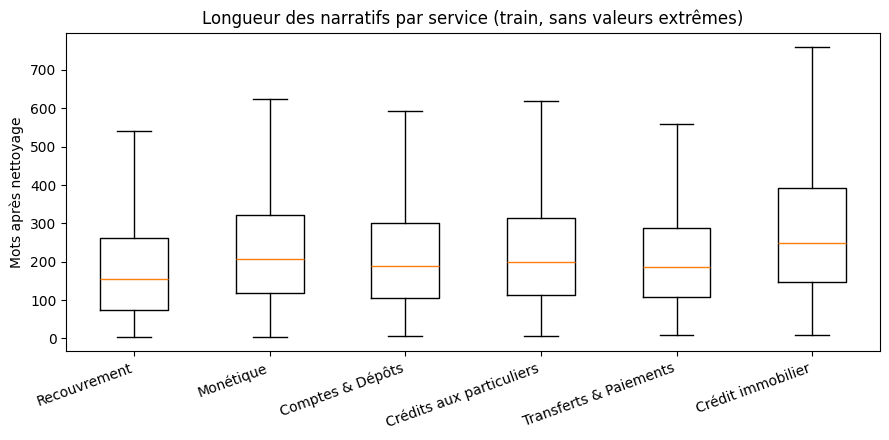

In [2]:
dist = (train.groupby("service").agg(n=("complaint_id", "size"),
                                     median_words=("n_words_clean", "median"),
                                     p95_words=("n_words_clean", lambda s: s.quantile(0.95)))
        .assign(share_pct=lambda d: (100 * d["n"] / d["n"].sum()).round(2))
        .sort_values("n", ascending=False))
dist.to_csv(TAB / "distribution_by_service.csv")
display(dist)

order = dist.index.tolist()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.boxplot([train.loc[train["service"] == s, "n_words_clean"] for s in order], showfliers=False)
ax.set_xticks(range(1, len(order) + 1), order, rotation=20, ha="right")
ax.set_ylabel("Mots après nettoyage")
ax.set_title("Longueur des narratifs par service (train, sans valeurs extrêmes)")
fig.tight_layout(); fig.savefig(FIG / "phase2c_length_by_service.png", dpi=150); plt.show()

## 2. Jetons de masquage par service

`pct_texts` = part des narratifs contenant le jeton ; `mean_per_text` = nombre moyen d'occurrences par narratif.

token,[AMOUNT],[DATE],[REDACTED]
service,,,
Comptes & Dépôts,54.15,58.41,83.21
Crédit immobilier,44.83,67.01,87.72
Crédits aux particuliers,42.16,55.27,82.68
Monétique,54.47,58.88,85.77
Recouvrement,33.46,38.15,78.29
Transferts & Paiements,58.44,59.52,85.27


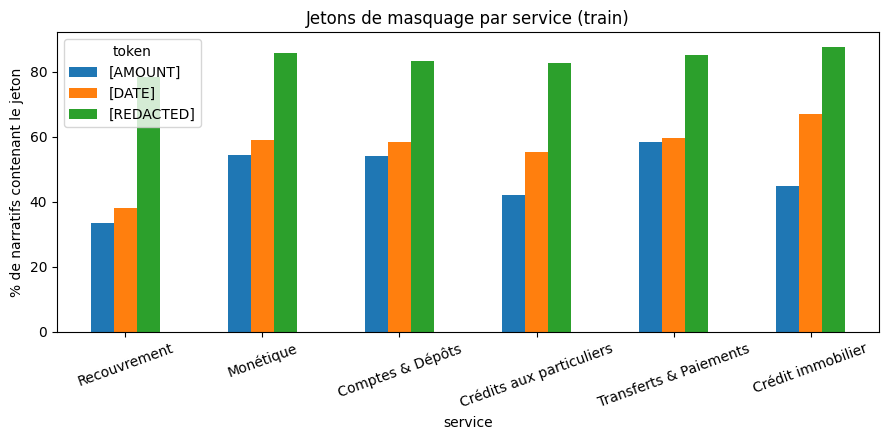

In [4]:
rows = []
for tok in TOKENS:
    cnt = train["text_clean"].str.count(re.escape(tok))
    for s in SERVICES:
        c = cnt[train["service"] == s]
        rows.append({"token": tok, "service": s, "pct_texts": round(100 * (c > 0).mean(), 2),
                     "mean_per_text": round(c.mean(), 2)})
tok_tab = pd.DataFrame(rows)
tok_tab.to_csv(TAB / "mask_tokens_by_service.csv", index=False)
display(tok_tab.pivot(index="service", columns="token", values="pct_texts"))

piv = tok_tab.pivot(index="service", columns="token", values="pct_texts").loc[order]
ax = piv.plot.bar(figsize=(9, 4.5), rot=20)
ax.set_ylabel("% de narratifs contenant le jeton"); ax.set_title("Jetons de masquage par service (train)")
plt.tight_layout(); plt.savefig(FIG / "phase2c_mask_tokens_by_service.png", dpi=150); plt.show()

## 3. Vocabulaire discriminant par service

Log-odds avec a priori de Dirichlet informatif (Monroe, Colaresi et Quinn, 2008) : chaque service est comparé à l'ensemble des autres ; l'a priori est la fréquence de chaque mot dans tout le jeu d'entraînement. Le score est un z-score : plus il est élevé, plus le mot est caractéristique du service.

Tokenisation : minuscules, mots alphabétiques ; jetons de masquage conservés ; mots outils anglais exclus ; mots vus moins de 50 fois exclus.

In [9]:
STOP = set(("the a an and or but to of in on at for with from by is was were are be been have has had i my me "
            "you your it this that they them their not no do did does as so if we our he she his her "
            "would could should will can there what when which who all any also about after into than then "
            "out up just only been being because over more very am").split())
WORD_RE = re.compile(r"\[(?:redacted|date|amount)\]|[a-z]+(?:'[a-z]+)?")

def tokens(text):
    return [w for w in WORD_RE.findall(text.lower()) if w not in STOP and (w.startswith("[") or len(w) > 2)]

docs = train["text_clean"].map(tokens)
by_service = {s: Counter() for s in SERVICES}
for s, toks in zip(train["service"], docs):
    by_service[s].update(toks)
total = Counter()
for c in by_service.values():
    total.update(c)
vocab = [w for w, n in total.items() if n >= 50]
counts = pd.DataFrame({s: [by_service[s].get(w, 0) for w in vocab] for s in SERVICES}, index=vocab)
alpha = counts.sum(axis=1).astype(float)          # informative prior = corpus counts
a0 = alpha.sum()
print(f"Vocabulaire retenu : {len(vocab):,} mots (sur {len(total):,})")

def log_odds_z(i):
    yi = counts[i]; yj = counts.drop(columns=i).sum(axis=1)
    ni, nj = yi.sum(), yj.sum()
    d = (np.log((yi + alpha) / (ni + a0 - yi - alpha)) - np.log((yj + alpha) / (nj + a0 - yj - alpha)))
    return d / np.sqrt(1 / (yi + alpha) + 1 / (yj + alpha))

z = pd.DataFrame({s: log_odds_z(s) for s in SERVICES})
z.to_csv(TAB / "log_odds_z_by_service.csv")
top = pd.DataFrame({s: pd.Series(z[s].nlargest(15).index.tolist(), dtype=object) for s in SERVICES})
top.index = top.index + 1
top.to_csv(TAB / "top15_discriminant_words.csv")
display(top)

Vocabulaire retenu : 6,399 mots (sur 42,967)


,Comptes & Dépôts,Crédit immobilier,Crédits aux particuliers,Monétique,Recouvrement,Transferts & Paiements
1,bank,mortgage,loan,card,debt,paypal
2,funds,escrow,vehicle,synchrony,collection,app
3,check,foreclosure,loans,merchant,validation,cash
4,transactions,servicing,mohela,citi,reporting,funds
5,checking,loan,student,express,alleged,money
6,branch,modification,repossession,charge,collect,transaction
7,deposit,servicer,car,american,fdcpa,transfer
8,chime,property,repayment,credit,credit,coinbase
9,wells,mitigation,dealership,one,creditor,recipient
10,fargo,rocket,payments,capital,original,wire


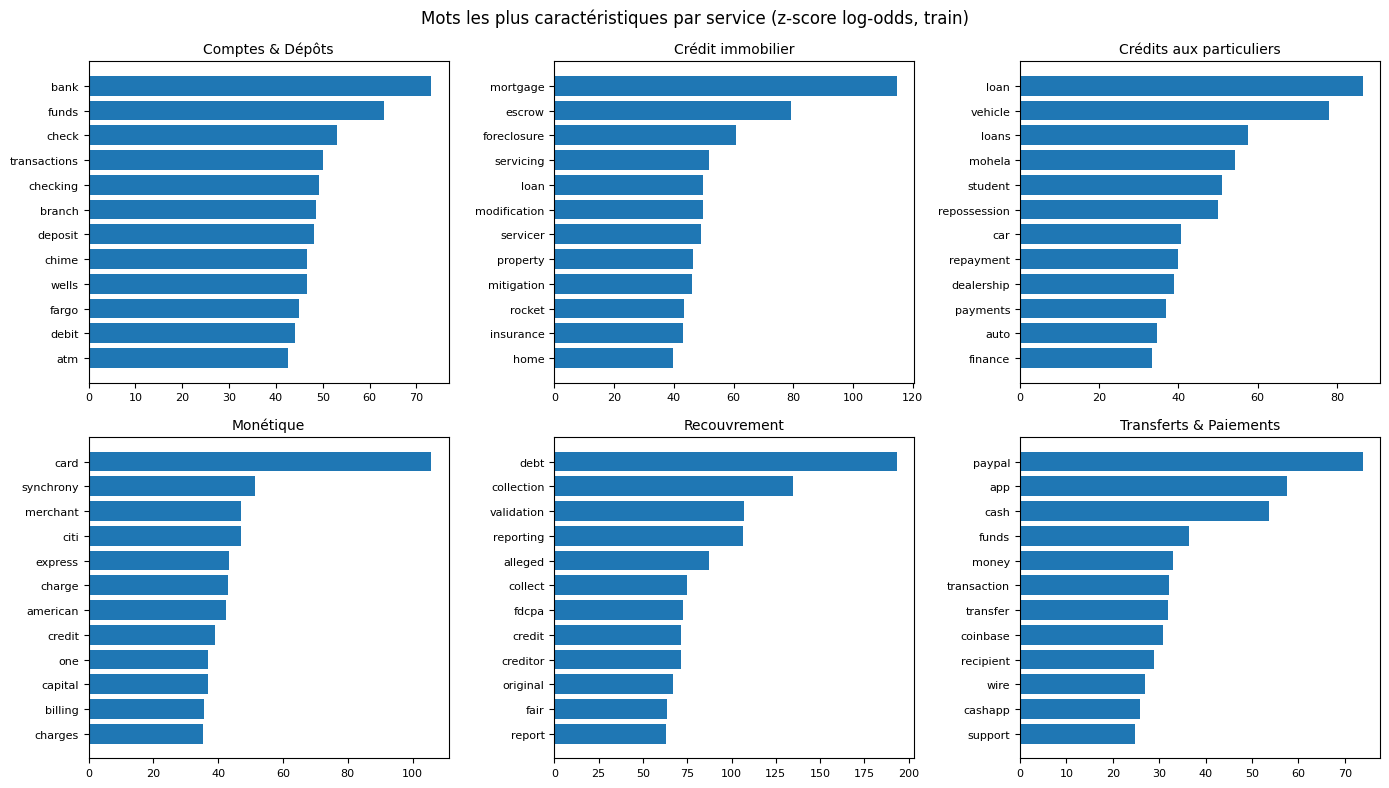

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, s in zip(axes.ravel(), SERVICES):
    t = z[s].nlargest(12)[::-1]
    ax.barh(t.index, t.values)
    ax.set_title(s, fontsize=10); ax.tick_params(labelsize=8)
fig.suptitle("Mots les plus caractéristiques par service (z-score log-odds, train)")
fig.tight_layout(); fig.savefig(FIG / "phase2c_discriminant_words.png", dpi=150); plt.show()

## 4. Bigrammes les plus fréquents par service

Bigrammes formés de deux mots consécutifs après exclusion des mots outils ; les bigrammes composés uniquement de jetons de masquage sont exclus.

In [14]:
big = {s: Counter() for s in SERVICES}
for s, toks in zip(train["service"], docs):
    big[s].update(f"{a} {b}" for a, b in zip(toks, toks[1:]) if not (a.startswith("[") and b.startswith("[")))
top_big = pd.DataFrame({s: pd.Series([f"{b} ({n:,})" for b, n in big[s].most_common(15)], dtype=object)
                        for s in SERVICES})
top_big.index = top_big.index + 1
top_big.to_csv(TAB / "top15_bigrams.csv")
display(top_big)

,Comptes & Dépôts,Crédit immobilier,Crédits aux particuliers,Monétique,Recouvrement,Transferts & Paiements
1,"wells fargo (6,662)","loss mitigation (2,188)","credit reporting (2,496)","credit card (11,327)","credit reporting (11,261)","cash app (5,482)"
2,"checking account (4,004)","rocket mortgage (1,494)","student loan (1,605)","capital one (5,955)","alleged debt (8,996)","[redacted] account (1,449)"
3,"bank america (3,771)","loan modification (1,249)","complaint regarding (1,400)","american express (3,259)","credit report (8,606)","wells fargo (1,263)"
4,"debit card (3,607)","escrow account (1,177)","approximately [amount] (1,295)","customer service (3,154)","debt collection (7,418)","bank account (1,209)"
5,"customer service (2,402)","mortgage payment (1,078)","credit report (1,254)","bank america (3,145)","original creditor (6,493)","account [redacted] (1,124)"
6,"[redacted] account (2,226)",credit reporting (897),"federal student (1,242)","wells fargo (2,811)","fair credit (6,015)",customer service (860)
7,"capital one (2,197)",wells fargo (880),"filing complaint (1,169)","card account (2,148)","collection practices (5,879)",filing complaint (779)
8,"account [redacted] (2,077)",approximately [amount] (852),"auto loan (1,130)","credit reporting (2,059)","reporting agencies (5,262)",bank america (735)
9,"provisional credit (2,031)",freedom mortgage (840),"payment history (1,121)","synchrony bank (1,995)","reporting act (5,230)",paypal account (722)
10,"cash app (1,974)",mortgage servicing (795),student loans (989),"complaint regarding (1,944)","fair debt (5,200)",number [redacted] (714)


## 5. Exemples par service

Deux narratifs tirés au hasard par service (graine du découpage), 300 premiers caractères du texte nettoyé.

In [15]:
ex = (train.groupby("service").sample(2, random_state=cfg["phase2"]["split"]["seed"])
          [["complaint_id", "service", "product", "text_clean"]]
          .assign(text_300=lambda d: d["text_clean"].str[:300]).drop(columns="text_clean"))
display(ex)

,complaint_id,service,product,text_300
44939,21616583,Comptes & Dépôts,Checking or savings account,"[DATE] , I discovered my identity was used without permission to open fraudulent bank accounts at [REDACTED] , Chase..."
47362,21773758,Comptes & Dépôts,Checking or savings account,"Since [DATE] , I have been unable to properly access or use my account with [REDACTED] . I have attempted to withdra..."
55026,22530317,Crédit immobilier,Mortgage,"To Whom It May Concern, I am submitting this complaint against Freedom Mortgage regarding their repeated failure to ..."
21383,19881662,Crédit immobilier,Mortgage,"I am submitting a complaint regarding my experience with a mortgage lender, [REDACTED] at Green River Capital, durin..."
45165,21632663,Crédits aux particuliers,Vehicle loan or lease,I am filing a complaint regarding the inaccurate and misleading credit reporting of my Harley-Davidson account [REDA...
21886,19906732,Crédits aux particuliers,Vehicle loan or lease,I am filing this complaint due to repeated failed attempts to contact Flagship Financial Group regarding my loan and...
73826,24442796,Monétique,Credit card,"In [DATE] , I accepted a Wells Fargo promotional balance-transfer offer with a 0 % APR through [DATE] . Wells Fargo ..."
5070,18668244,Monétique,Credit card,my credit report shows i opened a [REDACTED] credit line via [REDACTED] on [DATE] -and already have soent half that ...
28272,20277712,Recouvrement,Debt collection,"On [DATE] , I served a formal "" Debt Validation Demand '' via certified mail to [REDACTED] , the legal counsel for M..."
15839,19345587,Recouvrement,Debt collection,PenFed applied Collateral Protection Insurance ( CPI ) charges to my auto loan during a period when I was in the pro...


## Constats factuels

Rédigé le 2026-10-05 à partir des sorties ci-dessus (jeu d'entraînement, 74 415 narratifs), sans interprétation de modélisation :

- **Répartition :** de 29,68 % (Recouvrement, 22 084) à 7,31 % (Crédit immobilier, 5 438), soit un rapport de 4,1 entre la classe la plus fréquente et la plus rare.
- **Longueur médiane :** de 154 mots (Recouvrement) à 248 mots (Crédit immobilier) ; 95e centile de 520 à 838 mots.
- **Jetons de masquage :** `[REDACTED]` présent dans 78,29 % (Recouvrement) à 87,72 % (Crédit immobilier) des narratifs ; `[DATE]` de 38,15 % (Recouvrement) à 67,01 % (Crédit immobilier) ; `[AMOUNT]` de 33,46 % (Recouvrement) à 58,44 % (Transferts & Paiements). Recouvrement a la plus faible présence des trois jetons.
- **Vocabulaire discriminant :** le premier mot de chaque service est *bank* (Comptes & Dépôts), *mortgage* (Crédit immobilier), *loan* (Crédits aux particuliers), *card* (Monétique), *debt* (Recouvrement) et *paypal* (Transferts & Paiements). Les listes contiennent des noms d'entreprises (*chime*, *wells*, *fargo* ; *rocket*, *shellpoint* ; *mohela*, *nelnet*, *affirm* ; *synchrony*, *citi*, *barclays* ; *paypal*, *coinbase*, *cashapp*, *venmo*) et, pour Recouvrement, des références juridiques (*fdcpa*, *fcra*, *validation*, *cease*).
- **Bigrammes :** « credit reporting » est le bigramme le plus fréquent en Recouvrement (11 261) et en Crédits aux particuliers (2 496), alors que le produit *Credit reporting* est exclu du périmètre ; « wells fargo » est le plus fréquent en Comptes & Dépôts (6 662).